In [23]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterGrid

In [3]:
df = pd.read_csv("weather_dataset_2024_2026.csv", parse_dates=["time"])

train = df[df["time"].dt.year == 2024]
val = df[df["time"].dt.year == 2025]
test = df[df["time"].dt.year == 2026]

print("Training:", train.shape)
print("Validation:", val.shape)
print("Testing:", test.shape)

Training: (2208, 13)
Validation: (2208, 13)
Testing: (2208, 13)


In [4]:
features = [
    "temperature_ECMWF",
    "temperature_GFS",
    "temperature_ICON_EU"
]

target = "actual_temperature"

X_train = train[features]
y_train = train[target]

X_val = val[features]
y_val = val[target]

In [6]:
lr = LinearRegression()

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_val)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_val, lr_pred))
print("RMSE:", root_mean_squared_error(y_val, lr_pred))

Linear Regression
MAE: 1.075505726869139
RMSE: 1.4023368291606384


In [8]:
comparison = pd.DataFrame({
    "Actual": y_val.values,
    "Predicted": lr_pred,
    "ICON-EU": val["temperature_ICON_EU"].values
})

display(comparison.head(10))

,Actual,Predicted,ICON-EU
0,10.4,8.785878,8.9
1,8.7,8.106132,8.2
2,7.7,7.356383,7.3
3,6.6,6.883920,6.7
4,5.8,6.635230,6.3
5,5.2,7.501194,7.3
6,6.5,8.995779,8.9
7,9.7,10.933132,10.9
8,12.1,12.494598,12.5
9,13.7,14.214218,14.4


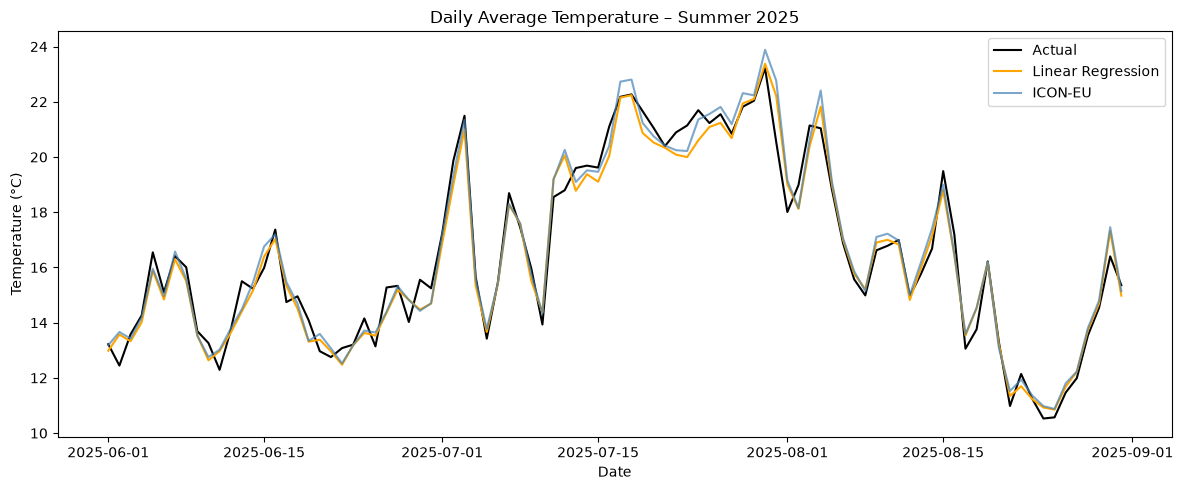

In [19]:
daily = pd.DataFrame({
    "time": val["time"].values,
    "Actual": y_val.values,
    "Linear Regression": val_pred,
    "ICON-EU": val["temperature_ICON_EU"].values
})

daily = daily.set_index("time").resample("D").mean()

plt.figure(figsize=(12, 5))

plt.plot(daily.index, daily["Actual"], label="Actual", color="black")
plt.plot(daily.index, daily["Linear Regression"], label="Linear Regression", color="orange")
plt.plot(daily.index, daily["ICON-EU"], label="ICON-EU", color="steelblue", alpha=0.7)

plt.title("Daily Average Temperature – Summer 2025")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
print("ICON-EU")
print("MAE:", mean_absolute_error(y_val, val["temperature_ICON_EU"]))
print("RMSE:", root_mean_squared_error(y_val, val["temperature_ICON_EU"]))

print("\nLinear Regression")
print("MAE:", mean_absolute_error(y_val, lr_pred))
print("RMSE:", root_mean_squared_error(y_val, lr_pred))

ICON-EU
MAE: 1.0879528985507245
RMSE: 1.4104103113551076

Linear Regression
MAE: 1.075505726869139
RMSE: 1.4023368291606384


In [15]:
for feature, coefficient in zip(features, lr.coef_):
    print(f"{feature}: {coefficient:.4f}")

print(f"Intercept: {lr.intercept_:.4f}")

temperature_ECMWF: 0.2657
temperature_GFS: -0.0806
temperature_ICON_EU: 0.8009
Intercept: 0.0344


In [40]:
rf = RandomForestRegressor(
    n_estimators=250,
    random_state=42,
    max_depth=5,
    min_samples_leaf=10,
    max_features=1.0
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_val)

print("Random Forest")
print("MAE:", mean_absolute_error(y_val, rf_pred))
print("RMSE:", root_mean_squared_error(y_val, rf_pred))

Random Forest
MAE: 1.123431176278016
RMSE: 1.454185916191418
